# Прогнозирование стоимости недвижимости

## Постановка задачи

Построить и протестировать несколько моделей регрессии, которые предсказывают цену объекта недвижимости по его характеристикам, и сделать приложение с формой ввода, дашбордом и справкой.

## Этап 1. Исследование данных (EDA)

### 1.1 Знакомство с данными

Загружаем датасет и смотрим его размер, первые и последние строки и одну случайную строку.

In [1]:
# библиотеки для работы с данными и графиками
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# читаем датасет из папки data
df = pd.read_csv("../data/real_estate_data.csv")
print("Размер датасета (строк, столбцов):", df.shape)

# первые 10 строк
df.head(10)

Размер датасета (строк, столбцов): (403487, 17)


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY
5,6,Konut,Rezidans,11/9/18,12/9/18,1,30,2,10-20 arası,10,1+1,45.0,İstanbul/Maltepe/Altayçeşme,NaN,Fancoil,780000.0,TRY
6,7,Konut,Daire,1/4/19,NaN,2,54,0,20 ve üzeri,14,3+1,160.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3750.0,TRY
7,8,Konut,Villa,10/3/18,1/3/19,1,92,0,4,NaN,4+1,NaN,İzmir/Urla/M. Fevzi Çakmak,NaN,Fancoil,1500000.0,TRY
8,9,Konut,Daire,2/16/19,NaN,1,11,NaN,2,Kot 2,3+1,140.0,Çanakkale/Ayvacık/Küçükkuyu Bld. (Mıhlı),NaN,Fancoil,1500000.0,TRY
9,10,Konut,Daire,12/26/18,12/26/18,1,0,1,1,Asma Kat,2+2,550.0,İstanbul/Fatih/Sarıdemir,NaN,Fancoil,84256.0,GBP


In [3]:
# последние 5 строк
df.tail()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
403482,403483,Konut,Daire,9/18/18,NaN,2,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,NaN,1500.0,TRY
403483,403484,Konut,Daire,10/11/18,NaN,1,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,NaN,120000.0,TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,48000.0,EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.0,Aydın/Kuşadası/Türkmen,NaN,NaN,900.0,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.0,Kayseri/Melikgazi/Alpaslan,NaN,NaN,210000.0,TRY


In [4]:
# одна случайная строка
df.sample(1, random_state=42)

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
60623,60624,Konut,Daire,11/20/18,2/23/19,1,95,6-10 arası,5,1,2+1,120.0,Antalya/Alanya/Oba,NaN,Klima,240000.0,TRY


### Описание признаков (по документации Zingat)

1. id — номер объявления;
2. type — категория недвижимости (Konut — жильё);
3. sub_type — подтип объекта (Daire — квартира, Villa — вилла, Rezidans — резиденция, Müstakil Ev — частный дом и т.д.);
4. start_date — дата публикации;
5. end_date — дата снятия с публикации;
6. listing_type — тип сделки (1 — продажа, 2 — аренда, 3 — прочее);
7. tom (time on market) — сколько дней объявление было на сайте;
8. building_age — возраст здания (0, 1, 2, 6-10 arası и т.д.);
9. total_floor_count — этажей в доме;
10. floor_no — этаж объекта;
11. room_count — планировка в формате «комнаты + гостиная» (2+1, 3+1);
12. size — площадь, м²;
13. address — адрес в виде город / район / микрорайон;
14. furnished — есть ли мебель;
15. heating_type — тип отопления (Kombi, Merkezi Sistem и др.);
16. price — цена, целевая переменная;
17. price_currency — валюта цены (TRY, USD, EUR, GBP).

In [5]:
# типы данных и количество непустых значений
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  str    
 15  price              402772 non-null  float64
 16  price_currenc

Пропуски есть в 9 столбцах, это видно по Non-Null Count. Числовых столбцов 6 (3 float64 и 3 int64), остальные 11 текстовые.

### 1.2 Описательная статистика

In [6]:
# статистика по числовым столбцам
df.describe()

,id,listing_type,tom,size,furnished,price
count,403487.00000,403487.000000,403487.000000,257481.000000,0.0,4.027720e+05
mean,201744.00000,1.294235,57.022739,279.349094,NaN,3.546417e+05
std,116476.80837,0.467733,44.358933,9429.195331,NaN,4.809503e+06
min,1.00000,1.000000,0.000000,1.000000,NaN,-2.500000e+02
25%,100872.50000,1.000000,29.000000,85.000000,NaN,2.500000e+03
50%,201744.00000,1.000000,40.000000,110.000000,NaN,1.990000e+05
75%,302615.50000,2.000000,90.000000,140.000000,NaN,3.420000e+05
max,403487.00000,3.000000,180.000000,948235.000000,NaN,2.000000e+09


По числовым признакам:

1. listing_type — пропусков нет, медиана 1, то есть объявлений о продаже больше, чем об аренде.
2. tom — в среднем объявление висит 57 дней, максимум 180.
3. size — есть пропуски, медиана 110 м², а максимум 948 235 м², значит есть явные выбросы.
4. furnished — столбец полностью пустой.
5. price — есть отрицательные цены (минимум -250) и пропуски, максимум намного больше медианы.

In [7]:
# статистика по текстовым столбцам: число уникальных и самое частое значение
df.describe(include='O')

,type,sub_type,start_date,end_date,building_age,total_floor_count,floor_no,room_count,address,heating_type,price_currency
count,403487,403487,403487,266298,376097,375466,368191,403487,403487,375517,402772
unique,1,12,181,181,14,12,44,37,7842,16,4
top,Konut,Daire,10/11/18,12/19/18,0,4,2,3+1,Balıkesir/Edremit/Akçay,Kombi (Doğalgaz),TRY
freq,403487,354549,4064,3048,140174,83082,60914,157363,5611,204150,400677


По текстовым признакам:

1. type — одно значение Konut (жильё), для модели бесполезен.
2. sub_type — 12 категорий, чаще всего квартиры (Daire).
3. start_date и end_date — 181 уникальный день, у end_date есть пропуски (объявление ещё активно).
4. building_age — чаще всего новые здания, есть пропуски.
5. total_floor_count и floor_no — чаще всего 4-этажные дома и 2-й этаж, есть пропуски.
6. room_count — 37 вариантов, чаще всего 3+1.
7. address — 7 842 уникальных адреса, чаще всего Balıkesir/Edremit/Akçay.
8. heating_type — чаще всего газовый котёл Kombi (Doğalgaz), есть пропуски.
9. price_currency — почти всё в лирах (TRY), остальные валюты нужно перевести.

In [8]:
# медиана, среднее и асимметрия цены
print(f"Медиана цены: {df['price'].median():,.2f}")
print(f"Средняя цена: {df['price'].mean():,.2f}")
print(f"Коэффициент асимметрии: {df['price'].skew():.2f}")

# асимметрия после логарифмирования (берём только положительные цены)
print(f"Асимметрия после log1p: {np.log1p(df.loc[df['price'] > 0, 'price']).skew():.2f}")

Медиана цены: 199,000.00
Средняя цена: 354,641.66
Коэффициент асимметрии: 308.51
Асимметрия после log1p: -0.81


Медиана 199 000, а среднее 354 642: дорогие объекты сильно тянут среднее вверх. Асимметрия 308.51, то есть очень длинный хвост вправо. После логарифмирования она падает до -0.81, поэтому модели будем учить на логарифме цены.

### 1.3 Визуальный анализ

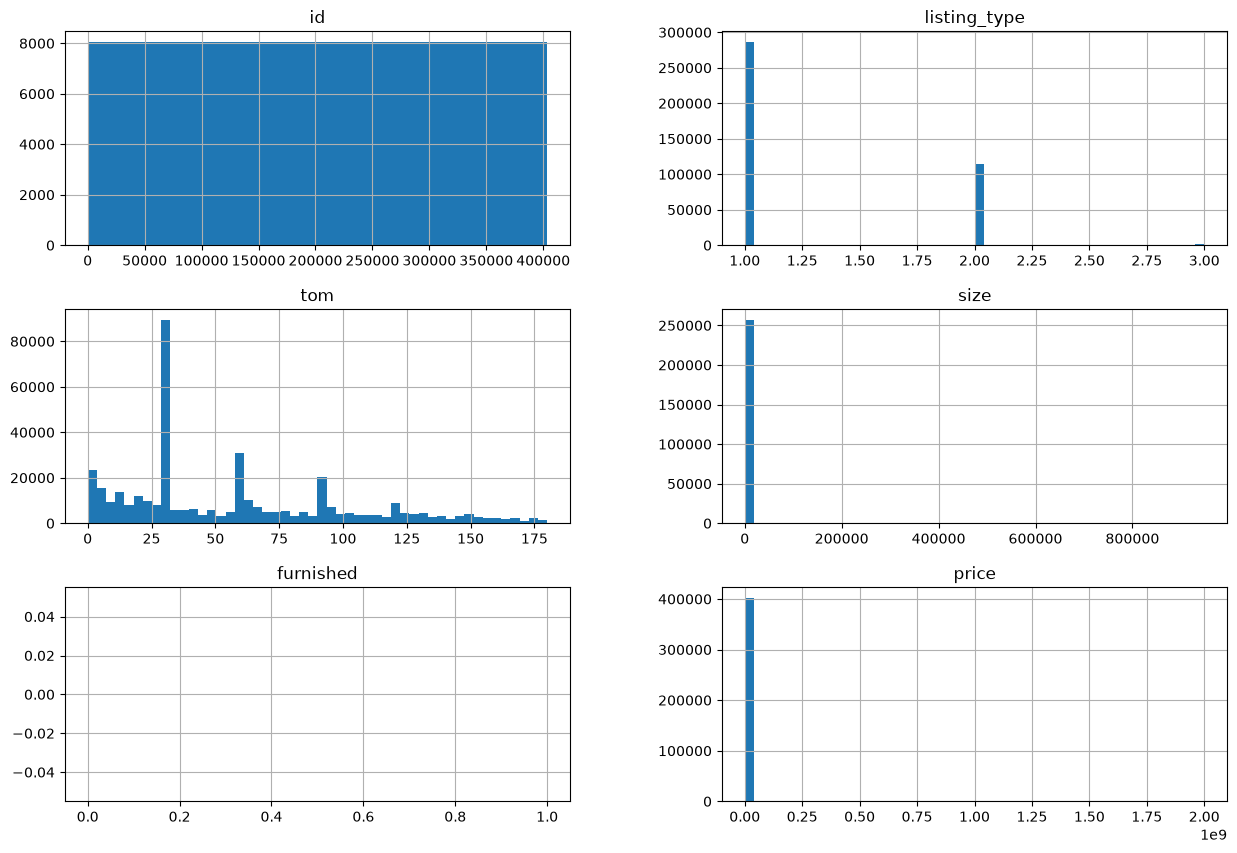

In [9]:
# 1. гистограммы числовых признаков
df.hist(figsize=(15, 10), bins=50)
plt.show()

По гистограммам:

1. id — просто номер, информации не несёт.
2. listing_type — больше всего продажи (1), меньше аренды (2), тип 3 почти не встречается.
3. tom — пики на 30, 60 и 90 днях.
4. size — график прижат к нулю из-за выбросов до 1 000 000 м².
5. furnished — пустой, удаляем.
6. price — длинный хвост справа, нужно логарифмирование.

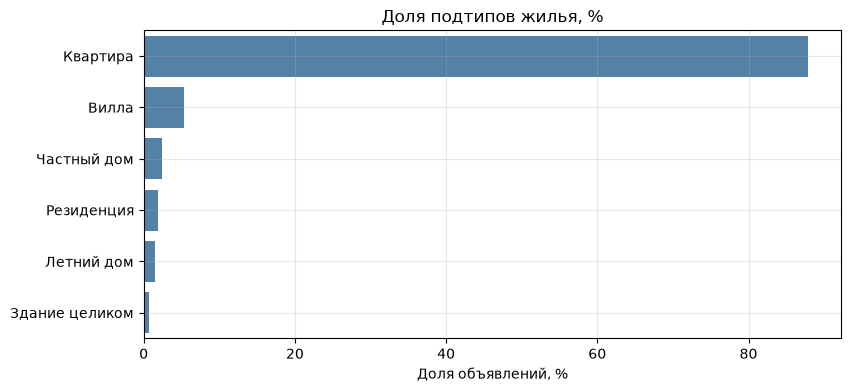

In [10]:
# 2. доли подтипов жилья, названия переводим на русский
sub_type_ru = {
    'Daire': 'Квартира', 'Villa': 'Вилла', 'Rezidans': 'Резиденция',
    'Müstakil Ev': 'Частный дом', 'Yazlık': 'Летний дом', 'Komple Bina': 'Здание целиком',
    'Çiftlik Evi': 'Фермерский дом', 'Köşk / Konak / Yalı': 'Особняк',
    'Yalı Dairesi': 'Квартира у воды', 'Kooperatif': 'Кооператив',
    'Prefabrik Ev': 'Сборный дом', 'Loft': 'Лофт'
}
sub_share = df['sub_type'].map(sub_type_ru).value_counts(normalize=True).head(6) * 100

plt.figure(figsize=(9, 4))
sns.barplot(x=sub_share.values, y=sub_share.index, color='steelblue')
plt.title('Доля подтипов жилья, %')
plt.xlabel('Доля объявлений, %')
plt.ylabel('')
plt.grid(True, alpha=0.3)
plt.show()

Почти 88% объявлений это квартиры (Daire). Виллы около 5%, остальные подтипы меньше 3% каждый.

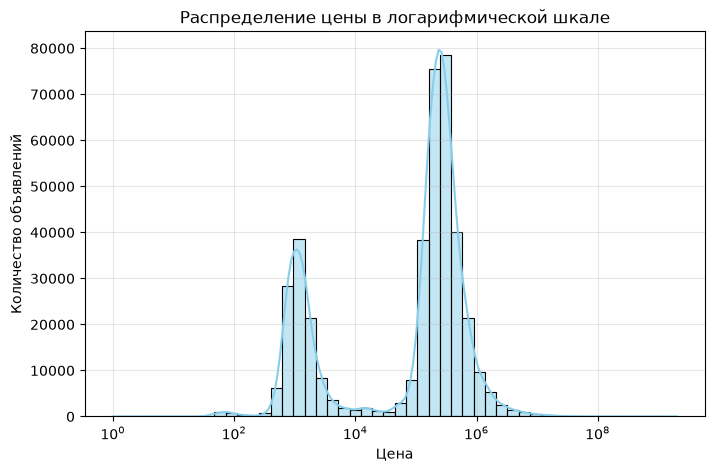

In [11]:
# 3. распределение цены в логарифмической шкале
plt.figure(figsize=(8, 5))
valid_prices = df[df['price'] > 0]['price']
sns.histplot(valid_prices, bins=50, log_scale=True, kde=True, color='skyblue')
plt.title('Распределение цены в логарифмической шкале')
plt.xlabel('Цена')
plt.ylabel('Количество объявлений')
plt.grid(True, alpha=0.3)
plt.show()

На графике два пика: аренда (примерно 10 000–30 000 лир) и продажа (около 200 000 лир). Справа длинный хвост из дорогих объектов.

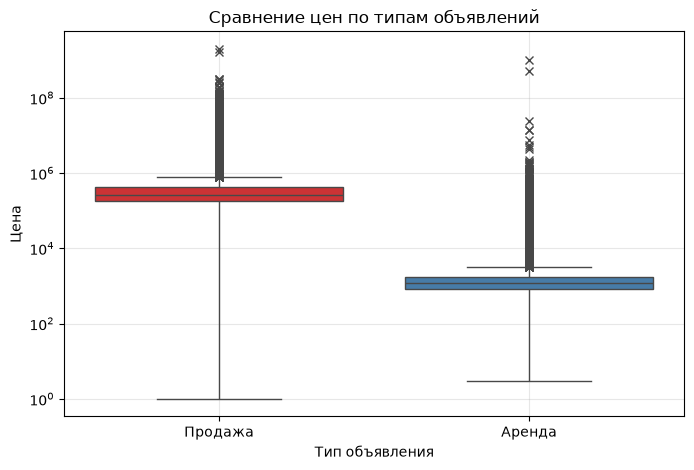

In [12]:
# 4. цены продажи и аренды
plt.figure(figsize=(8, 5))
df_filtered_listing = df[(df['price'] > 0) & (df['listing_type'].isin([1, 2]))]
sns.boxplot(data=df_filtered_listing, x='listing_type', y='price', palette='Set1', flierprops={'marker': 'x'})

plt.yscale('log')
plt.title('Сравнение цен по типам объявлений')
plt.xlabel('Тип объявления')
plt.ylabel('Цена')
plt.xticks([0, 1], ['Продажа', 'Аренда'])
plt.grid(True, alpha=0.3)
plt.show()

Продажа стоит сотни тысяч лир, аренда несколько тысяч. Точки сверху это выбросы, их уберём на этапе 2.

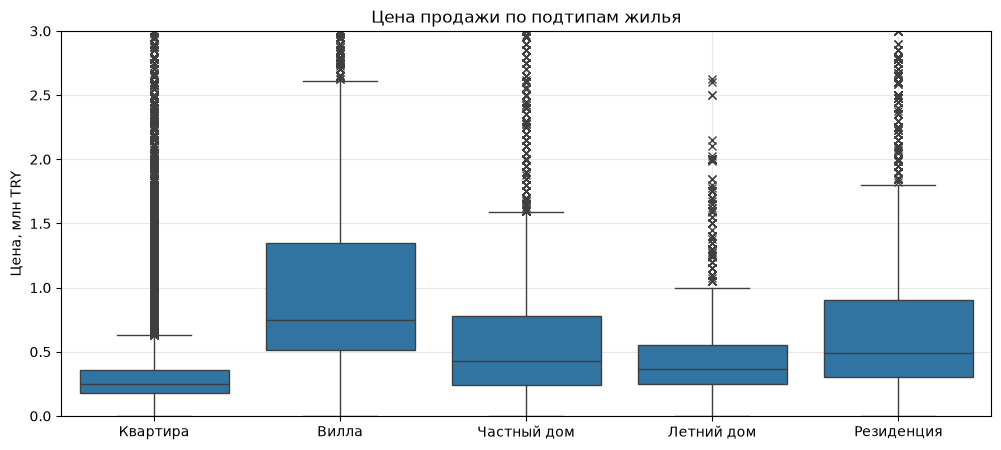

In [13]:
# 5. цена продажи по подтипам жилья (топ-5 подтипов)
sale = df[(df['listing_type'] == 1) & (df['price'] > 0)]
top5_sub = sale['sub_type'].value_counts().head(5).index.tolist()

plt.figure(figsize=(12, 5))
sns.boxplot(x=sale.loc[sale['sub_type'].isin(top5_sub), 'sub_type'],
            y=sale.loc[sale['sub_type'].isin(top5_sub), 'price'] / 1e6,
            order=top5_sub, flierprops={'marker': 'x'})
plt.xticks(range(5), [sub_type_ru[s] for s in top5_sub])
plt.title('Цена продажи по подтипам жилья')
plt.xlabel('')
plt.ylabel('Цена, млн TRY')
plt.ylim(0, 3)
plt.grid(True, alpha=0.3)
plt.show()

Дороже всего виллы, медиана около 750 000 лир. У квартир медиана около 250 000, но очень много выбросов вверх. Частные дома, резиденции и летние дома посередине.

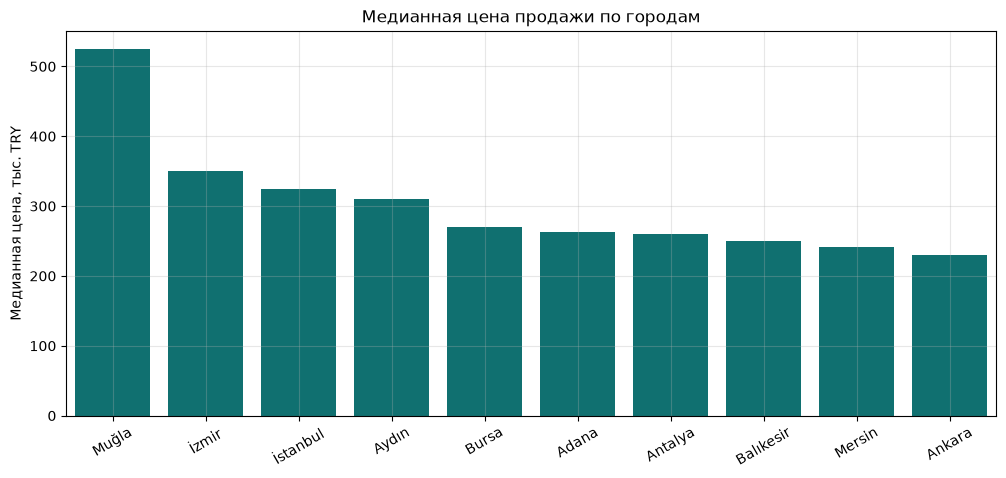

In [14]:
# 6. медианная цена продажи в 10 городах с наибольшим числом объявлений
sale_city = sale['address'].astype(str).str.split('/').str[0].str.strip()
top10_city = sale_city.value_counts().head(10).index
city_median = sale.groupby(sale_city)['price'].median()[top10_city].sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=city_median.index, y=city_median.values / 1000, color='teal')
plt.title('Медианная цена продажи по городам')
plt.xlabel('')
plt.ylabel('Медианная цена, тыс. TRY')
plt.xticks(rotation=30)
plt.grid(True, alpha=0.3)
plt.show()

Среди 10 городов с наибольшим числом объявлений дороже всего курортная Мугла (медиана 525 000 лир). Дальше идут Измир и Стамбул, дешевле всего Мерсин и Анкара.

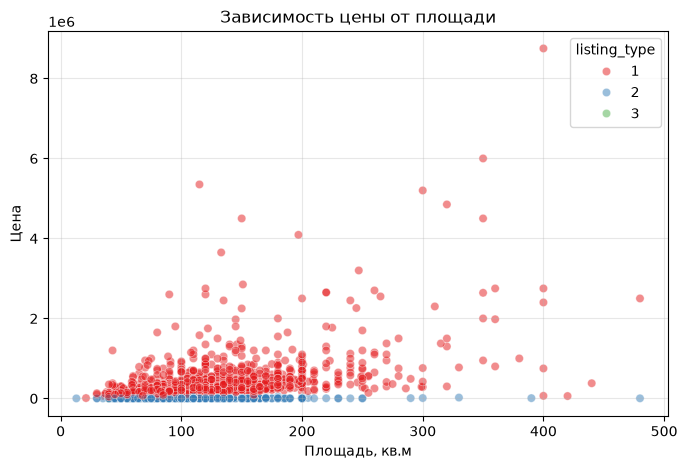

In [15]:
# 7. зависимость цены от площади
plt.figure(figsize=(8, 5))
df_size_price = df[(df['price'] > 0) & (df['price'] < 10000000) & (df['size'] > 10) & (df['size'] < 500)]
sns.scatterplot(data=df_size_price.sample(2000, random_state=42), x='size', y='price', hue='listing_type', alpha=0.5, palette='Set1')

plt.title('Зависимость цены от площади')
plt.xlabel('Площадь, кв.м')
plt.ylabel('Цена')
plt.grid(True, alpha=0.3)
plt.show()

Чем больше площадь, тем дороже, но разброс большой: на цену сильно влияют город и район.

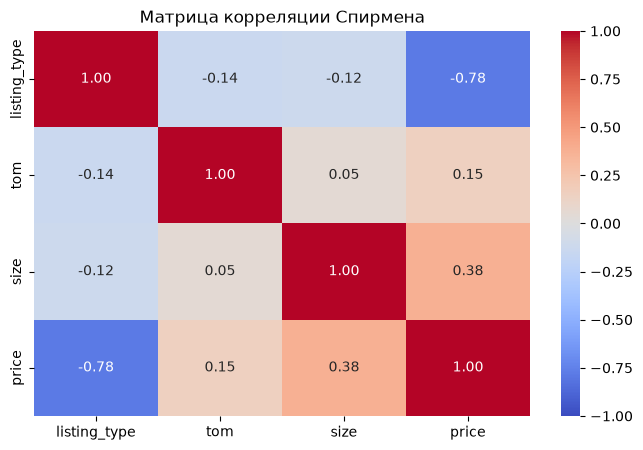

In [16]:
# 8. корреляция Спирмена
plt.figure(figsize=(8, 5))
corr = df[['listing_type', 'tom', 'size', 'price']].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)

plt.title('Матрица корреляции Спирмена')
plt.show()

Что сильнее всего связано с ценой:

1. Тип сделки (продажа или аренда): -0.78.
2. Площадь: +0.38, чем больше метров, тем дороже.
3. Время на рынке: +0.15, дорогие объекты продаются чуть дольше.

### 1.4 Пропуски, дубликаты, аномалии

In [17]:
# таблица пропусков по столбцам
null_info = pd.DataFrame({
    'Пропусков': df.isna().sum(),
    'Процент': (df.isna().sum() / len(df) * 100).round(2)
})
null_info[null_info['Пропусков'] > 0].sort_values('Процент', ascending=False)

,Пропусков,Процент
furnished,403487,100.00
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price,715,0.18
price_currency,715,0.18


Больше всего пропусков в furnished (100%), size (36%) и end_date (34%). У floor_no, total_floor_count, heating_type и building_age 7–9%, у price и price_currency по 0.18%.

In [18]:
# полные дубликаты и нереалистичные значения
print("Полных дубликатов:", df.duplicated().sum())
print("Полных дубликатов без учёта id:", df.drop(columns=['id']).duplicated().sum())
print("Записей с ценой <= 0:", (df['price'] <= 0).sum())
print("Записей с площадью <= 0:", (df['size'] <= 0).sum())

# в каких валютах указаны цены
df['price_currency'].value_counts(dropna=False)

Полных дубликатов: 0
Полных дубликатов без учёта id: 11455
Записей с ценой <= 0: 45
Записей с площадью <= 0: 0


price_currency
TRY    400677
EUR       922
NaN       715
GBP       621
USD       552
Name: count, dtype: int64

С учётом id полных дубликатов нет, но без id их 11 455: одно и то же объявление выложено несколько раз под разными номерами. Объявлений с ценой меньше или равной нулю 45, нулевой или отрицательной площади нет. Кроме лир встречаются EUR, GBP и USD, но их всего около 2 000.

### 1.5 Гипотезы

**Гипотеза 1.** Столбец furnished пустой на 100%, его можно удалить.

**Гипотеза 2.** start_date и end_date хранятся как текст, их нужно перевести в datetime.

**Гипотеза 3.** Часть цен указана в EUR, USD и GBP. Чтобы сравнивать цены, всё нужно перевести в лиры (TRY).

**Гипотеза 4.** building_age, total_floor_count и floor_no содержат текстовые диапазоны (например, "20 ve üzeri" — 20 и больше). Их нужно закодировать для моделей.

**Гипотеза 5.** У продажи (listing_type = 1) и аренды (listing_type = 2) цены отличаются на порядки, поэтому их лучше моделировать отдельно.

**Гипотеза 6.** Площадь будет самым сильным признаком для цены.

**Гипотеза 7.** Город тоже сильно влияет на цену: курортная Мугла и крупные Измир и Стамбул дороже остальных регионов.

## Этап 2. Предварительная обработка данных

Шаги:
1. 2.1 пропуски и дубликаты;
2. 2.2 комнаты и аномалии;
3. 2.3 даты;
4. 2.4 заполнение пропусков;
5. 2.5 валюта, выбросы, кодирование и масштабирование;
6. 2.6 разбиение на train и test.

### 2.1 Пропуски и дубликаты

Что делаем с каждым признаком:
1. id — служебный номер, удаляем. Без него в данных становятся видны полные дубликаты, их тоже удаляем.
2. furnished — 100% пропусков, удаляем.
3. listing_type — оставляем только продажу (1), аренда разбирается отдельно в ноутбуке model_testing.
4. price — пропусков 0.18%, строки без цены удаляем: целевую переменную заполнять нельзя.
5. size — пропусков 36%, удалять столько строк нельзя, поэтому заполняем медианой (шаг 2.4).
6. building_age, total_floor_count, floor_no, heating_type — пропуски заменяем на 'Unknown' (шаг 2.4).

In [19]:
# копия датасета, удаляем id и пустой furnished
df_clean = df.copy()
df_clean = df_clean.drop(columns=['id', 'furnished'], errors='ignore')

# без id появляются полные дубликаты, удаляем их
before_dup = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Удалено полных дубликатов: {before_dup - len(df_clean)}")

# оставляем только продажу
if 'listing_type' in df_clean.columns:
    df_clean = df_clean[df_clean['listing_type'] == 1].drop(columns=['listing_type'])

# удаляем строки без цены
before_price = len(df_clean)
df_clean = df_clean[df_clean['price'].notna()]
print(f"Удалено строк без цены: {before_price - len(df_clean)}")
print("Размер после шага 2.1:", df_clean.shape)

Удалено полных дубликатов: 11455
Удалено строк без цены: 349
Размер после шага 2.1: (278376, 14)


Удалили 11 455 дубликатов и 349 строк без цены. Осталось 278 376 объявлений о продаже.

### 2.2 Комнаты и аномалии

1. room_count хранится текстом вида "2+1", переводим в общее число комнат (2+1 = 3).
2. Цены меньше или равные нулю это ошибки ввода, удаляем.
3. Площадь меньше 5 или больше 2000 м² тоже ошибки, удаляем. Строки без площади оставляем.

In [20]:
# комнаты "2+1" -> 3
def parse_rooms(room_str):
    if pd.isna(room_str):
        return np.nan
    room_str = str(room_str).strip()
    if '+' in room_str:
        parts = room_str.split('+')
        try:
            return float(parts[0]) + float(parts[1])
        except:
            return np.nan
    try:
        return float(room_str)
    except:
        return np.nan

df_clean['room_count_num'] = df_clean['room_count'].apply(parse_rooms)
df_clean = df_clean.drop(columns=['room_count'], errors='ignore')

# удаляем некорректные цены
before_prices = len(df_clean)
df_clean2 = df_clean[df_clean['price'] > 0].copy()
print(f"Удалено записей с ценой <= 0: {before_prices - len(df_clean2)}")

# удаляем аномальную площадь, пустую площадь оставляем
size_anomalies = ((df_clean2['size'] < 5) | (df_clean2['size'] > 2000)).sum()
df_clean2 = df_clean2[(df_clean2['size'].isna()) | ((df_clean2['size'] >= 5) & (df_clean2['size'] <= 2000))]
print(f"Удалено аномальных значений площади: {size_anomalies}")
print("Размер после шага 2.2:", df_clean2.shape)

Удалено записей с ценой <= 0: 17
Удалено аномальных значений площади: 577
Размер после шага 2.2: (277782, 14)


Удалили 17 объявлений с ценой меньше или равной нулю и 577 с аномальной площадью. Осталось 277 782 строки.

### 2.3 Даты

start_date и end_date переводим из текста в datetime.

In [21]:
df_clean3 = df_clean2.copy()

# даты из текста в datetime
df_clean3['start_date'] = pd.to_datetime(df_clean3['start_date'], errors='coerce')
df_clean3['end_date'] = pd.to_datetime(df_clean3['end_date'], errors='coerce')

print(df_clean3[['start_date', 'end_date', 'price', 'size']].dtypes)

start_date    datetime64[us]
end_date      datetime64[us]
price                float64
size                 float64
dtype: object


Даты теперь в формате datetime.

### 2.4 Заполнение пропусков

1. size заполняем медианой по подтипу жилья и числу комнат: так квартира 2+1 получит площадь типичной квартиры 2+1. Что осталось, заполняем общей медианой.
2. В текстовых признаках пропуски заменяем на 'Unknown', чтобы не терять строки.

In [22]:
df_clean4 = df_clean3.copy()

# площадь: медиана по подтипу и числу комнат, потом общая медиана
df_clean4['size'] = df_clean4.groupby(['sub_type', 'room_count_num'])['size'].transform(lambda x: x.fillna(x.median()))
df_clean4['size'] = df_clean4['size'].fillna(df_clean4['size'].median())

# текстовые признаки: пропуски -> 'Unknown'
cat_cols = ['building_age', 'total_floor_count', 'floor_no', 'heating_type']
for col in cat_cols:
    df_clean4[col] = df_clean4[col].fillna('Unknown')

print("Осталось пропусков:")
print(df_clean4[['size', 'building_age', 'total_floor_count', 'floor_no', 'heating_type']].isna().sum())

Осталось пропусков:
size                 0
building_age         0
total_floor_count    0
floor_no             0
heating_type         0
dtype: int64


Пропусков в этих столбцах больше нет.

### 2.5 Валюта, выбросы, кодирование и масштабирование

1. Переводим цены в лиры по средним курсам: USD 5.3, EUR 6.0, GBP 6.8.
2. Оставляем цены от 50 000 до 5 000 000 лир и площадь от 10 до 1000 м².
3. Цену логарифмируем через np.log1p, потому что у неё сильный хвост вправо.
4. Из адреса берём город и район.
5. sub_type и heating_type кодируем через One-Hot: у этих категорий нет порядка, поэтому порядковое кодирование не подходит.
6. size и tom масштабируем через StandardScaler. Для линейной регрессии это нужно, деревьям не мешает.

In [23]:
from sklearn.preprocessing import StandardScaler

df_clean5 = df_clean4.copy()

# перевод цен в лиры по средним курсам
currency_rates = {'TRY': 1.0, 'USD': 5.3, 'EUR': 6.0, 'GBP': 6.8}
df_clean5['price_try'] = df_clean5.apply(
    lambda row: row['price'] * currency_rates.get(row['price_currency'], 1.0), axis=1
)

# выбросы по цене и площади
df_clean5 = df_clean5[(df_clean5['price_try'] >= 50000) & (df_clean5['price_try'] <= 5000000)]
df_clean5 = df_clean5[(df_clean5['size'].isna()) | ((df_clean5['size'] >= 10) & (df_clean5['size'] <= 1000))]

# логарифм цены
df_clean5['price_try_log'] = np.log1p(df_clean5['price_try'])

# город и район из адреса
df_clean5['city'] = df_clean5['address'].astype(str).str.split('/').str[0].str.strip()
df_clean5['district'] = df_clean5['address'].astype(str).str.split('/').str[1].str.strip()
print("Размер после фильтрации выбросов:", df_clean5.shape)

Размер после фильтрации выбросов: (274734, 18)


In [24]:
# One-Hot Encoding
categorical_cols = ['sub_type', 'heating_type']
df_clean5 = pd.get_dummies(df_clean5, columns=categorical_cols, drop_first=True)

# масштабирование size и tom
scaler = StandardScaler()
num_cols = ['size', 'tom']
df_clean5[num_cols] = scaler.fit_transform(df_clean5[num_cols])
print("Размер после кодирования:", df_clean5.shape)

Размер после кодирования: (274734, 43)


После перевода валют и фильтрации выбросов осталось 274 734 объявления, после One-Hot получилось 43 столбца.

### 2.6 Разбиение данных

1. Пропуски в комнатах заполняем медианой.
2. Для 10 самых частых городов делаем отдельные столбцы 0/1.
3. В X берём все числовые и логические столбцы, кроме цены. Целевая переменная — логарифм цены.
4. Делим на train и test 80/20 с random_state=42.

In [25]:
from sklearn.model_selection import train_test_split

# пропуски в комнатах заполняем медианой
df_clean5['room_count_num'] = df_clean5['room_count_num'].fillna(df_clean5['room_count_num'].median())

# One-Hot для топ-10 городов
top_cities = df_clean5['city'].value_counts().nlargest(10).index
for city in top_cities:
    df_clean5[f'city_{city}'] = (df_clean5['city'] == city).astype(int)

# признаки
X = df_clean5.select_dtypes(include=[np.number, bool]).drop(
    columns=['price', 'price_try', 'price_try_log'], errors='ignore'
)

# оставшиеся пропуски в X заполняем медианой
X = X.fillna(X.median())

# целевая переменная
y = df_clean5['price_try_log']

# разделение на train и test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

Размер X_train: (219787, 40)
Размер X_test: (54947, 40)


In [26]:
# сохраняем обработанный датасет, его использует дашборд в приложении
output_filename = '../data/real_estate_processed.csv'
df_clean5.to_csv(output_filename, index=False)

print(f"Обработанный датасет сохранен в файл: {output_filename}")
print(f"Итоговое количество строк: {df_clean5.shape[0]}")
print(f"Итоговое количество столбцов: {df_clean5.shape[1]}")

Обработанный датасет сохранен в файл: ../data/real_estate_processed.csv
Итоговое количество строк: 274734
Итоговое количество столбцов: 53


Предобработка закончена. В обучающей выборке 219 787 строк, в тестовой 54 947, признаков 40. Итоговый датасет (274 734 строки, 53 столбца) сохранён в data/real_estate_processed.csv, его использует дашборд в приложении.

## Этап 3. Построение модели регрессии

### 3.1 Выбор моделей регрессии

Взяли три модели:

1. LinearRegression — простая линейная модель, базовый вариант.
2. RandomForestRegressor — случайный лес, ансамбль деревьев на бэггинге, устойчив к выбросам.
3. CatBoostRegressor — градиентный бустинг, обычно лучше всего работает на табличных данных.

### 3.2 Обучение и выбор гиперпараметров

#### LinearRegression

In [27]:
# импорт библиотек
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV, cross_val_score

In [28]:
# базовая модель
base_lr = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [29]:
# оценка базовой модели на кросс-валидации (RMSE)
base_scores = cross_val_score(base_lr, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')

print("Базовая модель LinearRegression")
print(f"Базовый CV RMSE: {-base_scores.mean():,.2f}\n\n\n")

Базовая модель LinearRegression
Базовый CV RMSE: 0.47





Базовая модель: CV RMSE = 0.47.

In [30]:
# подбор гиперпараметров через GridSearchCV
param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid_lr = GridSearchCV(
    estimator=LinearRegression(),
    param_grid=param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LinearRegression(), n_jobs=-1,
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]},
             scoring='neg_root_mean_squared_error')

Перебираемые параметры:

1. fit_intercept — считать ли свободный член. При False прямая проходит через ноль.
2. positive — разрешать только положительные коэффициенты.

In [31]:
# фиксация лучших параметров
print("Результаты подбора гиперпараметров")
print("Лучшие гиперпараметры:", grid_lr.best_params_)
print(f"Лучший CV RMSE: {-grid_lr.best_score_:,.2f}\n\n\n")

Результаты подбора гиперпараметров
Лучшие гиперпараметры: {'fit_intercept': True, 'positive': False}
Лучший CV RMSE: 0.47





Лучшие параметры совпали с параметрами по умолчанию (fit_intercept=True, positive=False), CV RMSE остался 0.47. У линейной регрессии почти нечего настраивать, поэтому так и получилось.

In [32]:
# лучшая модель
best_lr_model = grid_lr.best_estimator_

#### RandomForestRegressor

In [33]:
# импорт библиотек
from sklearn.ensemble import RandomForestRegressor

In [34]:
# базовая модель
base_rf = RandomForestRegressor(random_state=42, n_jobs=-1)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [35]:
# оценка базовой модели
base_scores_rf = cross_val_score(base_rf, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)

print("Базовая модель RandomForestRegressor")
print(f"Базовый CV RMSE: {-base_scores_rf.mean():,.2f}\n\n\n")

Базовая модель RandomForestRegressor
Базовый CV RMSE: 0.45





У случайного леса без настройки CV RMSE = 0.45, это немного лучше линейной регрессии.

In [36]:
# подбор гиперпараметров через GridSearchCV
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15],
    'min_samples_split': [5, 10]
}

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid_rf,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [10, 15], 'min_samples_split': [5, 10],
                         'n_estimators': [50, 100]},
             scoring='neg_root_mean_squared_error')

Перебираемые параметры:

1. n_estimators — количество деревьев.
2. max_depth — максимальная глубина дерева.
3. min_samples_split — минимальное число объектов в узле, чтобы его разделить.

In [37]:
# фиксация лучших параметров
print("Результаты подбора гиперпараметров RandomForest")
print("Лучшие гиперпараметры:", grid_rf.best_params_)
print(f"Лучший CV RMSE: {-grid_rf.best_score_:,.2f}\n\n\n")

Результаты подбора гиперпараметров RandomForest
Лучшие гиперпараметры: {'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 100}
Лучший CV RMSE: 0.43





Лучшие параметры: max_depth = 15, min_samples_split = 10, n_estimators = 100. CV RMSE снизился до 0.43. Ограничения по глубине и размеру узла не дают деревьям подстраиваться под шум.

In [38]:
# лучшая модель
best_rf_model = grid_rf.best_estimator_

#### CatBoostRegressor

In [39]:
# импорт библиотек
from catboost import CatBoostRegressor

In [40]:
# базовая модель CatBoostRegressor
base_cb = CatBoostRegressor(random_state=42, verbose=0)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [41]:
# оценка базовой модели
base_scores_cb = cross_val_score(base_cb, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)

print("Базовая модель CatBoostRegressor")
print(f"Базовый CV RMSE: {-base_scores_cb.mean():,.2f}\n\n\n")

Базовая модель CatBoostRegressor
Базовый CV RMSE: 0.43





Базовый CatBoost даёт CV RMSE = 0.43, лучше базового леса.

In [42]:
# подбор гиперпараметров через GridSearchCV
param_grid_cb = {
    'iterations': [200, 500],
    'learning_rate': [0.03, 0.1],
    'depth': [4, 6]
}

grid_cb = GridSearchCV(
    estimator=CatBoostRegressor(random_state=42, verbose=0),
    param_grid=param_grid_cb,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_cb.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=CatBoostRegressor(loss_function='RMSE', random_state=42, verbose=0),
             n_jobs=-1,
             param_grid={'depth': [4, 6], 'iterations': [200, 500],
                         'learning_rate': [0.03, 0.1]},
             scoring='neg_root_mean_squared_error')

Перебираемые параметры:

1. iterations — количество деревьев (шагов бустинга).
2. learning_rate — скорость обучения. Чем она меньше, тем больше нужно итераций.
3. depth — глубина деревьев.

In [43]:
# фиксация лучших параметров
print("Результаты подбора гиперпараметров CatBoost")
print("Лучшие гиперпараметры:", grid_cb.best_params_)
print(f"Лучший CV RMSE: {-grid_cb.best_score_:,.2f}\n\n\n")

Результаты подбора гиперпараметров CatBoost
Лучшие гиперпараметры: {'depth': 6, 'iterations': 500, 'learning_rate': 0.1}
Лучший CV RMSE: 0.43





Лучшие параметры: depth = 6, iterations = 500, learning_rate = 0.1. CV RMSE = 0.43, как у базовой модели и у подобранного леса.

In [44]:
# лучшая модель
best_cb_model = grid_cb.best_estimator_

### 3.3 Метрики качества

Метрики:

1. MAE — средняя абсолютная ошибка.
2. RMSE — корень из среднеквадратичной ошибки, сильнее штрафует за большие промахи.
3. MAPE — средняя ошибка в процентах.
4. $R^2$ — какую долю разброса цен объясняет модель, чем ближе к 1, тем лучше.
5. Adjusted $R^2$ — то же самое, но со штрафом за лишние признаки.

Модели учились на логарифме цены, поэтому MAE и RMSE здесь тоже в логарифмах, а не в лирах.

In [45]:
# импорт библиотек
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

In [46]:
# функция для расчета всех 5 метрик
def evaluate_model(model, X_test, y_test, p_features):
    y_pred = model.predict(X_test)
    
    n = len(y_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)
    
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p_features - 1)
    
    return {
        'MAE (TRY)': mae,
        'RMSE (TRY)': rmse,
        'MAPE (%)': mape,
        'R²': r2,
        'Adjusted R²': adj_r2
    }

Функция, чтобы не повторять один и тот же код для каждой модели.

In [47]:
# количество признаков в обучающей выборке
num_features = X_train.shape[1]

# сбор метрик для каждой из трех моделей
results = {
    'LinearRegression': evaluate_model(best_lr_model, X_test, y_test, num_features),
    'RandomForestRegressor': evaluate_model(best_rf_model, X_test, y_test, num_features),
    'CatBoostRegressor': evaluate_model(best_cb_model, X_test, y_test, num_features)
}

In [48]:
# создание итоговой сравнительной таблицы
df_metrics = pd.DataFrame(results).T
pd.set_option('display.float_format', lambda x: '%.2f' % x)
display(df_metrics)

,MAE (TRY),RMSE (TRY),MAPE (%),R²,Adjusted R²
LinearRegression,0.35,0.47,2.77,0.52,0.52
RandomForestRegressor,0.32,0.43,2.52,0.60,0.60
CatBoostRegressor,0.32,0.43,2.52,0.61,0.61


Итоги по таблице:

1. MAE: у леса и CatBoost 0.32, у линейной регрессии 0.35.
2. RMSE: 0.43 против 0.47, деревья реже сильно ошибаются.
3. MAPE: 2.52% у леса и CatBoost, 2.77% у линейной регрессии.
4. $R^2$: 0.61 у CatBoost, 0.60 у леса, 0.52 у линейной регрессии. Остальной разброс, скорее всего, из-за того, что в данных нет точного местоположения.

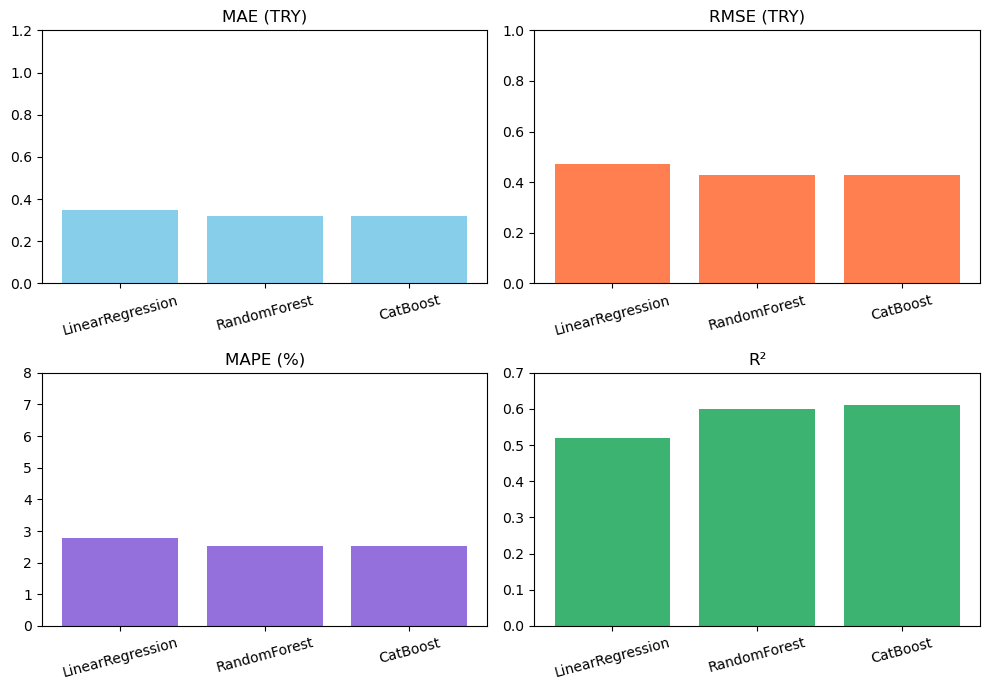

In [49]:
# значения из таблицы метрик
models = ['LinearRegression', 'RandomForest', 'CatBoost']
mae = [0.35, 0.32, 0.32]
rmse = [0.47, 0.43, 0.43]
mape = [2.77, 2.52, 2.52]
r2 = [0.52, 0.60, 0.61]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# MAE
axes[0, 0].bar(models, mae, color='skyblue')
axes[0, 0].set_title('MAE (TRY)')
axes[0, 0].set_ylim(0, 1.2)

# RMSE
axes[0, 1].bar(models, rmse, color='coral')
axes[0, 1].set_title('RMSE (TRY)')
axes[0, 1].set_ylim(0, 1.0)

# MAPE
axes[1, 0].bar(models, mape, color='mediumpurple')
axes[1, 0].set_title('MAPE (%)')
axes[1, 0].set_ylim(0, 8)

# R²
axes[1, 1].bar(models, r2, color='mediumseagreen')
axes[1, 1].set_title('R²')
axes[1, 1].set_ylim(0, 0.7)

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Лес и CatBoost заметно лучше линейной регрессии и почти одинаковы между собой. Выбрали CatBoost: у него чуть выше $R^2$, и он быстрее предсказывает.

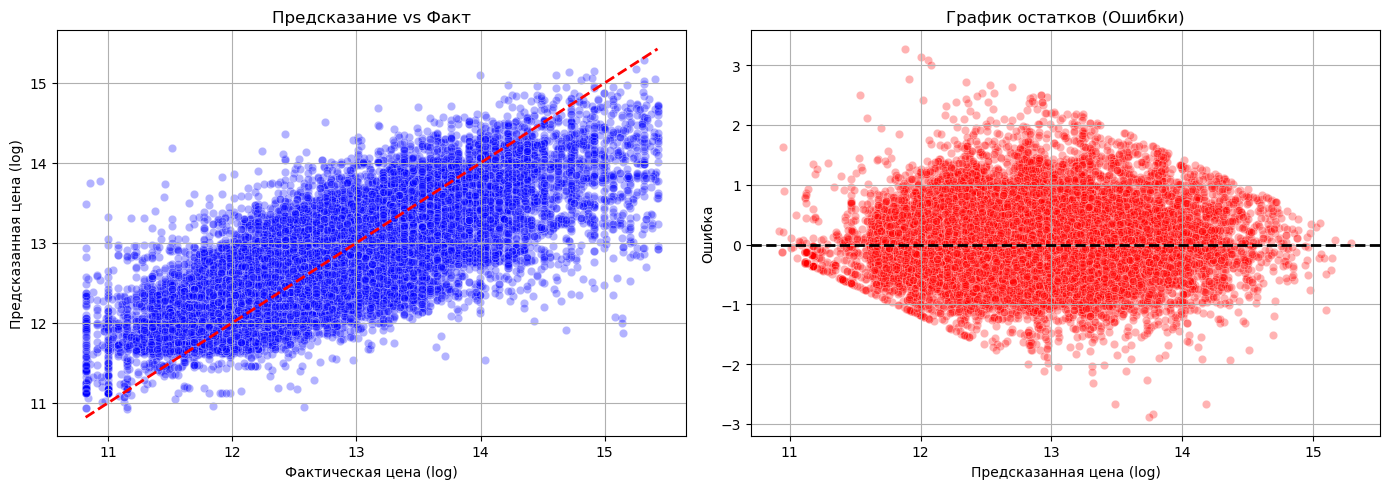

In [50]:
# графики для CatBoost
y_pred = best_cb_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# предсказание vs Факт
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, ax=axes[0], color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Предсказание vs Факт')
axes[0].set_xlabel('Фактическая цена (log)')
axes[0].set_ylabel('Предсказанная цена (log)')
axes[0].grid(True)

# остатки
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3, ax=axes[1], color='red')
axes[1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1].set_title('График остатков (Ошибки)')
axes[1].set_xlabel('Предсказанная цена (log)')
axes[1].set_ylabel('Ошибка')
axes[1].grid(True)

plt.tight_layout()
plt.show()

На графике «Предсказание vs Факт» точки идут вдоль красной линии, в основном в диапазоне 12–14. Дешёвые объекты модель немного завышает, дорогие немного занижает.

Остатки разбросаны вокруг нуля без явной закономерности, так что модель ошибается примерно одинаково по всему диапазону.

In [51]:
# важность признаков для Случайного Леса (RandomForest)
rf_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

In [52]:
# важность признаков для CatBoost
cb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_cb_model.get_feature_importance()
}).sort_values(by='Importance', ascending=False)

In [53]:
# коэффициенты для Линейной регрессии (LinearRegression)
lr_coefs = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': best_lr_model.coef_
}).sort_values(by='Coefficient', key=abs, ascending=False)

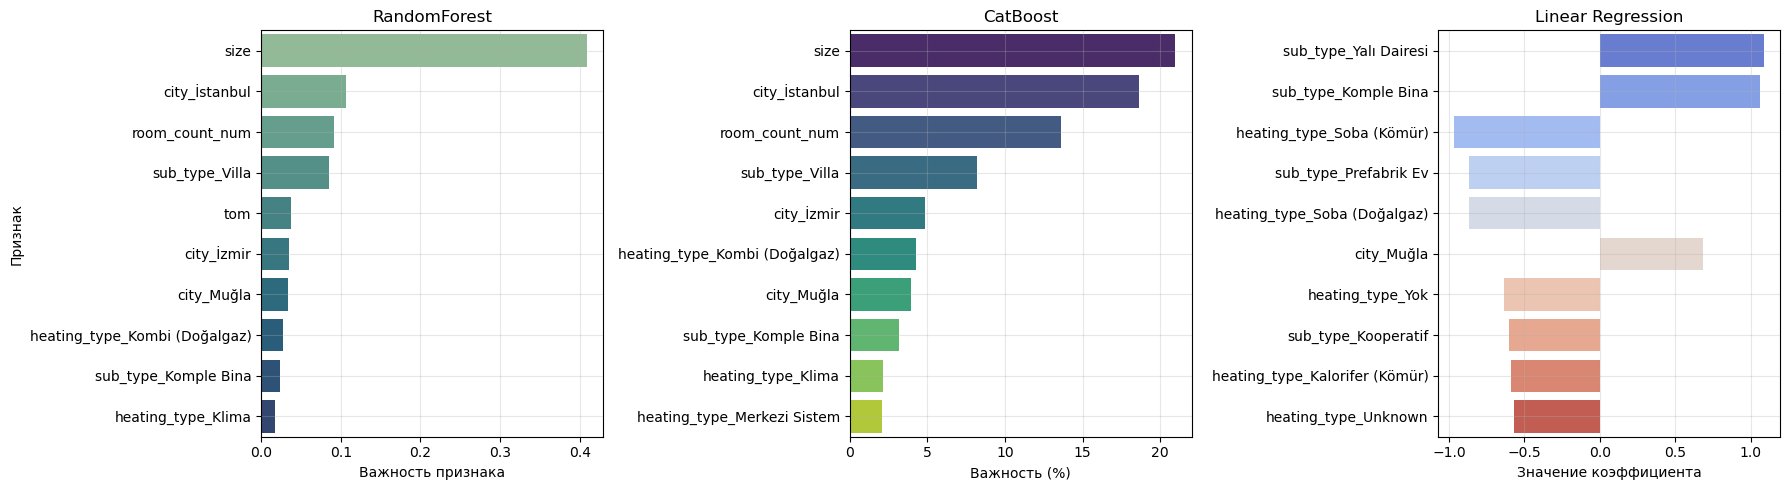

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# график RandomForest
sns.barplot(data=rf_importance.head(10), x='Importance', y='Feature', ax=axes[0], palette='crest')
axes[0].set_title('RandomForest')
axes[0].set_xlabel('Важность признака')
axes[0].set_ylabel('Признак')
axes[0].grid(True, alpha=0.3)

# график CatBoost
sns.barplot(data=cb_importance.head(10), x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('CatBoost')
axes[1].set_xlabel('Важность (%)')
axes[1].set_ylabel('')
axes[1].grid(True, alpha=0.3)

# график LinearRegression
sns.barplot(data=lr_coefs.head(10), x='Coefficient', y='Feature', ax=axes[2], palette='coolwarm')
axes[2].set_title('Linear Regression')
axes[2].set_xlabel('Значение коэффициента')
axes[2].set_ylabel('')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Важность признаков:

1. У леса и CatBoost главный признак — площадь (size): около 40% у леса и больше 20% у CatBoost. Дальше идут Стамбул (city_İstanbul) и число комнат (room_count_num).
2. Также заметны виллы (sub_type_Villa) и города Измир и Мугла. Время на рынке (tom) влияет слабо, меньше 5%.
3. У линейной регрессии смотрим на коэффициенты. Сильнее всего цену поднимают квартиры у воды (sub_type_Yalı Dairesi) и здания целиком (sub_type_Komple Bina), сильнее всего снижают печное отопление (heating_type_Soba) и сборные дома (sub_type_Prefabrik Ev).

### 3.4 Выбор финальной модели

Финальная модель — CatBoostRegressor:

1. По точности на уровне случайного леса и лучше линейной регрессии (MAPE 2.52%).
2. Предсказывает быстрее леса, для приложения это удобно.
3. Есть встроенная регуляризация, меньше риск переобучения.

In [55]:
import joblib

joblib.dump(best_cb_model, '../models/catboost_model.pkl')

['../models/catboost_model.pkl']

In [56]:
# сохранение scaler
joblib.dump(scaler, '../models/scaler.pkl')

# сохранение списка признаков
model_columns = list(X_train.columns)
joblib.dump(model_columns, '../models/model_columns.pkl')

['../models/model_columns.pkl']